### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [ ]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [ ]:
# TODO: print the shape of the dataset
# TODO: use .info() to see column dtypes and non-null counts

print("Dataset Shape:", titanic.shape)

print("\nDataset Information:")
titanic.info()

Dataset Shape: (891, 15)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [ ]:
# TODO: call .describe() on titanic

titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

Missing Value Summary:


,Missing Values,Percentage (%)
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
age,177,19.865320
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000
embarked,2,0.224467
class,0,0.000000
who,0,0.000000


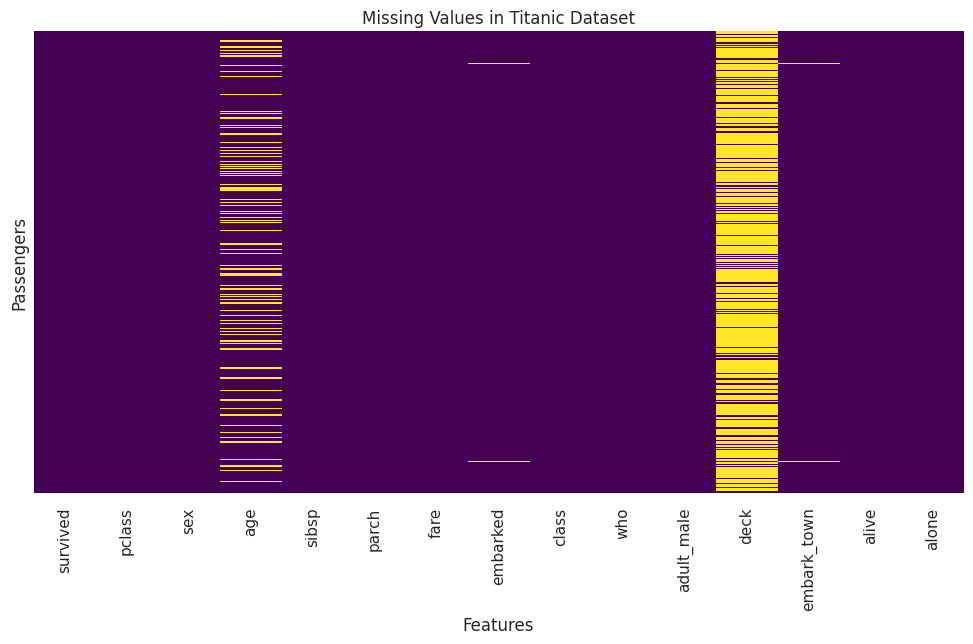

In [ ]:
# TODO: compute titanic.isnull().sum()
missing_count = titanic.isnull().sum()

# TODO: also compute it as a percentage of total rows
missing_percentage = (titanic.isnull().sum() / len(titanic)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percentage
})

print("Missing Value Summary:")
display(missing_summary)

# TODO (visualization): plot a heatmap of missing values, e.g.
# sns.heatmap(titanic.isnull(), cbar=False)
plt.figure(figsize=(12, 6))
sns.heatmap(titanic.isnull(), cbar=False, yticklabels=False, cmap='viridis')

plt.title('Missing Values in Titanic Dataset')
plt.xlabel('Features')
plt.ylabel('Passengers')
plt.show()

**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

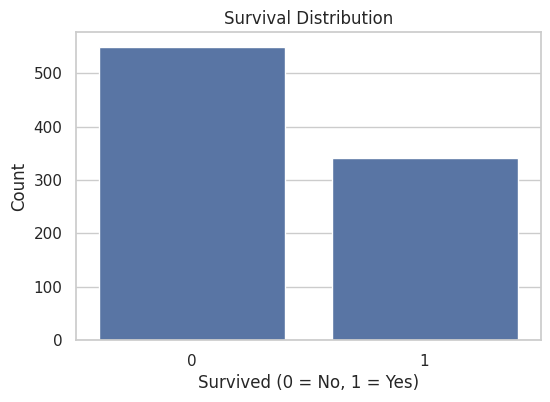

Survival Percentage Distribution:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [ ]:
# TODO: sns.countplot the 'survived' column
plt.figure(figsize=(6, 4))
sns.countplot(data=titanic, x='survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# TODO: print the exact percentage split (value_counts(normalize=True))
survival_percentage = titanic['survived'].value_counts(normalize=True) * 100

print("Survival Percentage Distribution:")
print(survival_percentage)

**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

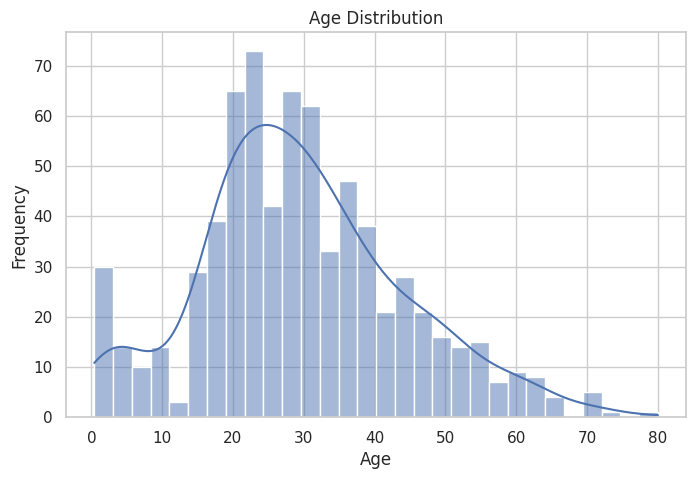

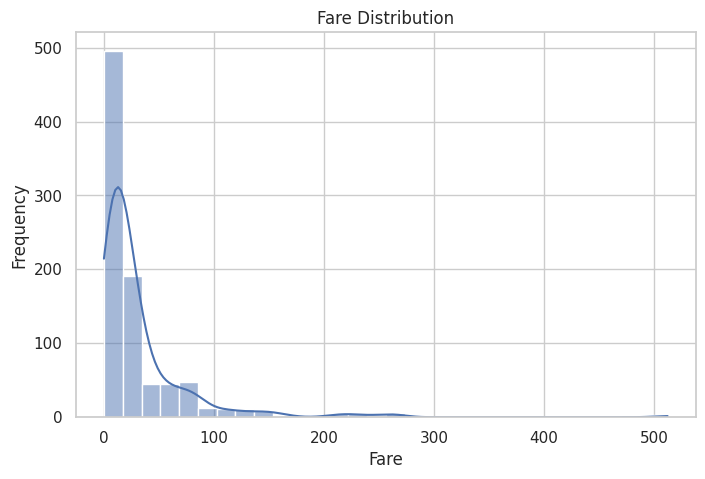

Age Skewness: 0.38910778230082704
Fare Skewness: 4.787316519674893


In [ ]:
# TODO: plot a histogram (with KDE) of 'age'
plt.figure(figsize=(8, 5))
sns.histplot(titanic['age'], kde=True, bins=30)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# TODO: plot a histogram (with KDE) of 'fare'
plt.figure(figsize=(8, 5))
sns.histplot(titanic['fare'], kde=True, bins=30)

plt.title('Fare Distribution')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.show()

# TODO: print titanic['age'].skew() and titanic['fare'].skew()
print("Age Skewness:", titanic['age'].skew())
print("Fare Skewness:", titanic['fare'].skew())

**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

Survival Rate by Sex:
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

Survival Rate by Passenger Class:
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


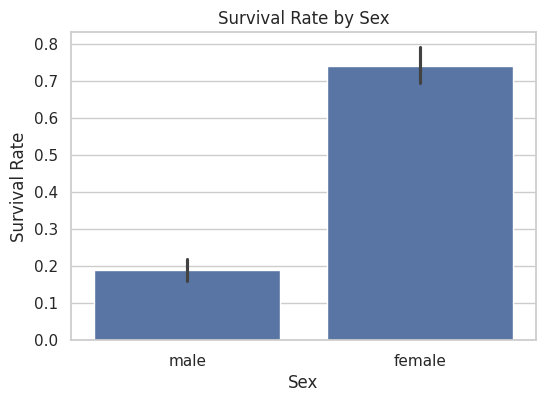

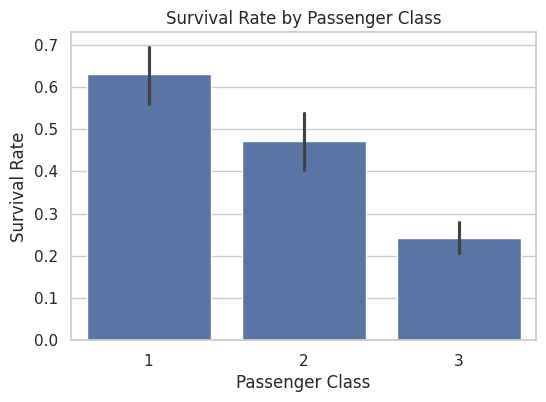

In [ ]:
# TODO: titanic.groupby('sex')['survived'].mean()
survival_by_sex = titanic.groupby('sex')['survived'].mean()

print("Survival Rate by Sex:")
print(survival_by_sex)

# TODO: titanic.groupby('pclass')['survived'].mean()
survival_by_class = titanic.groupby('pclass')['survived'].mean()

print("\nSurvival Rate by Passenger Class:")
print(survival_by_class)

# TODO: visualize both with sns.barplot or sns.catplot
plt.figure(figsize=(6, 4))
sns.barplot(data=titanic, x='sex', y='survived')

plt.title('Survival Rate by Sex')
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(data=titanic, x='pclass', y='survived')

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [ ]:
# TODO: P_A = P(Survived = 1)          -> titanic['survived'].mean()
P_A = titanic['survived'].mean()

# TODO: P_B = P(Sex = female)             -> (titanic['sex'] == 'female').mean()
P_B = (titanic['sex'] == 'female').mean()

# TODO: P_B_given_A = P(Sex=female | Survived=1)
#       hint: filter titanic where survived == 1, then compute the fraction that are female
survivors = titanic[titanic['survived'] == 1]
P_B_given_A = (survivors['sex'] == 'female').mean()

# TODO: apply Bayes' Theorem: P_A_given_B = (P_B_given_A * P_A) / P_B
P_A_given_B = (P_B_given_A * P_A) / P_B

# TODO: print P_A_given_B and compare it to titanic.groupby('sex')['survived'].mean()['female'] from Section 1.6
# They should match (up to rounding) - if not, recheck your probabilities above!
print("P(Survived = 1):", P_A)
print("P(Sex = female):", P_B)
print("P(Sex = female | Survived = 1):", P_B_given_A)

print("\nUsing Bayes' Theorem:")
print("P(Survived = 1 | Sex = female):", P_A_given_B)

empirical_value = titanic.groupby('sex')['survived'].mean()['female']

print("\nEmpirical value from groupby:", empirical_value)
print("Do they match?", np.isclose(P_A_given_B, empirical_value))

P(Survived = 1): 0.3838383838383838
P(Sex = female): 0.35241301907968575
P(Sex = female | Survived = 1): 0.6812865497076024

Using Bayes' Theorem:
P(Survived = 1 | Sex = female): 0.7420382165605095

Empirical value from groupby: 0.7420382165605095
Do they match? True


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [ ]:
from sklearn.model_selection import train_test_split

# Keep a focused set of columns for this lab
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']
df = titanic[cols].copy()

# TODO: X = df.drop(columns=['survived']), y = df['survived']
X = df.drop(columns=['survived'])
y = df['survived']


# TODO: train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       name the results X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (712, 7)
X_test shape: (179, 7)
y_train shape: (712,)
y_test shape: (179,)


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [ ]:
from sklearn.impute import SimpleImputer

# TODO: num_imputer = SimpleImputer(strategy='median')
num_imputer = SimpleImputer(strategy='median')

# TODO: fit num_imputer on X_train[['age']], then transform both X_train and X_test 'age' column
X_train['age'] = num_imputer.fit_transform(
    X_train[['age']]
).ravel()

X_test['age'] = num_imputer.transform(
    X_test[['age']]
).ravel()

# TODO: cat_imputer = SimpleImputer(strategy='most_frequent')
cat_imputer = SimpleImputer(strategy='most_frequent')

# Fit only on training data, then transform train and test
# TODO: fit cat_imputer on X_train[['embarked']], then transform both X_train and X_test 'embarked' column
X_train['embarked'] = cat_imputer.fit_transform(
    X_train[['embarked']]
).ravel()

X_test['embarked'] = cat_imputer.transform(
    X_test[['embarked']]
).ravel()

# TODO: confirm no missing values remain with .isnull().sum()
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Missing values in X_test:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [ ]:
age_bins = [0, 12, 19, 59, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# TODO: X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_train['age_group'] = pd.cut(
    X_train['age'],
    bins=age_bins,
    labels=age_labels
)

# TODO: do the same for X_test['age_group']
X_test['age_group'] = pd.cut(
    X_test['age'],
    bins=age_bins,
    labels=age_labels
)

# TODO: print value_counts() of the new column to sanity-check the split
print("Age group counts in X_train:")
print(X_train['age_group'].value_counts())

print("\nAge group counts in X_test:")
print(X_test['age_group'].value_counts())

Age group counts in X_train:
age_group
Adult     565
Teen       74
Child      55
Senior     18
Name: count, dtype: int64

Age group counts in X_test:
age_group
Adult     136
Teen       21
Child      14
Senior      8
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer

# TODO: kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
kb = KBinsDiscretizer(
    n_bins=4,
    encode='ordinal',
    strategy='quantile'
)

# TODO: fit kb on X_train[['fare']]
kb.fit(X_train[['fare']])

# TODO: X_train['fare_level'] = kb.transform(X_train[['fare']])
X_train['fare_level'] = kb.transform(X_train[['fare']]).ravel()

# TODO: X_test['fare_level']  = kb.transform(X_test[['fare']])
X_test['fare_level'] = kb.transform(X_test[['fare']]).ravel()

# TODO: print kb.bin_edges_ to see the learned edges
print("Learned Fare Bin Edges:")
print(kb.bin_edges_)

# Optional sanity check
print("\nFare level counts in X_train:")
print(X_train['fare_level'].value_counts().sort_index())

Learned Fare Bin Edges:
[array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]

Fare level counts in X_train:
fare_level
0.0    148
1.0    206
2.0    179
3.0    179
Name: count, dtype: int64


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [ ]:
from sklearn.preprocessing import Binarizer

# TODO: binarizer = Binarizer(threshold=12.9)   # threshold is exclusive (>), so 12.9 makes 13+ map to 1... check this makes <13 -> 0
binarizer = Binarizer(threshold=12.9)

X_train['is_child'] = 1 - binarizer.fit_transform(
    X_train[['age']]
).ravel()

X_test['is_child'] = 1 - binarizer.transform(
    X_test[['age']]
).ravel()

# TODO: X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
print("is_child counts in X_train:")
print(X_train['is_child'].value_counts())

print("\nSample check:")
print(X_train[['age', 'is_child']].head(10))

# TODO: X_test['is_child']  = binarizer.transform(X_test[['age']])


is_child counts in X_train:
is_child
0.0    657
1.0     55
Name: count, dtype: int64

Sample check:
      age  is_child
692  28.5       0.0
481  28.5       0.0
527  28.5       0.0
855  18.0       0.0
801  31.0       0.0
652  21.0       0.0
509  26.0       0.0
557  28.5       0.0
828  28.5       0.0
18   31.0       0.0


**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# --- Ordinal Encoding for age_group ---
# TODO: oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
oe = OrdinalEncoder(
    categories=[['Child', 'Teen', 'Adult', 'Senior']]
)

# TODO: fit oe on X_train[['age_group']], transform X_train and X_test 'age_group' column
X_train['age_group'] = oe.fit_transform(
    X_train[['age_group']]
).ravel()

# --- One-Hot Encoding for sex, embarked (we'll actually apply this via ColumnTransformer in 2.7) ---
# (no code needed here yet - just review the OneHotEncoder import above)
X_test['age_group'] = oe.transform(
    X_test[['age_group']]
).ravel()

print("Ordinal categories:")
print(oe.categories_)

print("\nEncoded age_group sample:")
print(X_train[['age', 'age_group']].head(10))
# No transformation here yet.
# We will apply OneHotEncoder through ColumnTransformer in Section 2.7.

# --- Label Encoding demo on titanic['alive'] ---
# TODO: le = LabelEncoder()
le = LabelEncoder()

# TODO: alive_encoded = le.fit_transform(titanic['alive'])
alive_encoded = le.fit_transform(titanic['alive'])

# TODO: print le.classes_ and the first 10 values of alive_encoded
print("\nLabelEncoder classes:")
print(le.classes_)

print("\nFirst 10 encoded values:")
print(alive_encoded[:10])

Ordinal categories:
[array(['Child', 'Teen', 'Adult', 'Senior'], dtype=object)]

Encoded age_group sample:
      age  age_group
692  28.5        2.0
481  28.5        2.0
527  28.5        2.0
855  18.0        1.0
801  31.0        2.0
652  21.0        2.0
509  26.0        2.0
557  28.5        2.0
828  28.5        2.0
18   31.0        2.0

LabelEncoder classes:
['no' 'yes']

First 10 encoded values:
[0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [ ]:
from sklearn.compose import ColumnTransformer

# TODO: define a ColumnTransformer with:
#   ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
# and remainder='passthrough' to keep age, age_group_encoded, fare, fare_level, is_child, pclass, sibsp, parch
from sklearn.preprocessing import OneHotEncoder

# Define the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            'ohe',
            OneHotEncoder(drop='first', handle_unknown='ignore'),
            ['sex', 'embarked']
        )
    ],
    remainder='passthrough'
)

# TODO: fit_transform on X_train (careful: only fit on train!), transform on X_test
X_train_transformed = preprocessor.fit_transform(X_train)

X_test_transformed = preprocessor.transform(X_test)

# TODO: print the resulting shapes of X_train and X_test after this step
print("X_train shape after ColumnTransformer:",
      X_train_transformed.shape)

print("X_test shape after ColumnTransformer:",
      X_test_transformed.shape)

X_train shape after ColumnTransformer: (712, 11)
X_test shape after ColumnTransformer: (179, 11)


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [ ]:
from sklearn.preprocessing import PowerTransformer

fare_skew_before = X_train['fare'].skew()
# TODO: pt = PowerTransformer(method='yeo-johnson')
pt = PowerTransformer(method='yeo-johnson')

# TODO: fit pt on the training 'fare' column, transform both train and test 'fare' columns
X_train['fare'] = pt.fit_transform(
    X_train[['fare']]
).ravel()

X_test['fare'] = pt.transform(
    X_test[['fare']]
).ravel()

# TODO: compare skewness of 'fare' before vs after using pandas .skew()
fare_skew_after = X_train['fare'].skew()

print("Fare skewness before transformation:", fare_skew_before)
print("Fare skewness after transformation:", fare_skew_after)

Fare skewness before transformation: 4.64618995113625
Fare skewness after transformation: -0.030504795464933083


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# TODO: choose StandardScaler() OR MinMaxScaler()
feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_final = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

# TODO: fit on the numeric columns of X_train, transform both X_train and X_test
numeric_cols = ['remainder__age', 'remainder__fare']

# TODO: name your final, fully-processed feature sets X_train_final and X_test_final
scaler = StandardScaler()

X_train_final[numeric_cols] = scaler.fit_transform(
    X_train_final[numeric_cols]
)

X_test_final[numeric_cols] = scaler.transform(
    X_test_final[numeric_cols]
)

print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)

print("\nScaled training numeric features:")
print(X_train_final[numeric_cols].describe())

X_train_final.head()

X_train_final shape: (712, 11)
X_test_final shape: (179, 11)

Scaled training numeric features:
       remainder__age  remainder__fare
count    7.120000e+02     7.120000e+02
mean     8.233115e-17     1.455764e-15
std      1.000703e+00     1.000703e+00
min     -2.238460e+00    -6.625632e-01
25%     -5.805160e-01    -4.981542e-01
50%     -8.113533e-02    -3.615930e-01
75%      4.950731e-01    -1.707070e-02
max      3.875496e+00     1.000533e+01


,ohe__sex_male,ohe__embarked_Q,ohe__embarked_S,remainder__pclass,remainder__age,remainder__sibsp,remainder__parch,remainder__fare,remainder__age_group,remainder__fare_level,remainder__is_child
692,1.0,0.0,1.0,3.0,-0.081135,0.0,0.0,0.513812,2.0,3.0,0.0
481,1.0,0.0,1.0,2.0,-0.081135,0.0,0.0,-0.662563,2.0,0.0,0.0
527,1.0,0.0,1.0,1.0,-0.081135,0.0,0.0,3.955399,2.0,3.0,0.0
855,0.0,0.0,1.0,3.0,-0.887827,0.0,1.0,-0.467874,1.0,1.0,0.0
801,0.0,0.0,1.0,2.0,0.110934,1.0,1.0,-0.115977,2.0,2.0,0.0


**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [ ]:
class GaussianNaiveBayesScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.mean = {}
        self.var = {}
        for c in self.classes:
            X_c = X[y == c]
            # TODO: self.priors[c] = P(y = c)  -> fraction of training rows with this class
            # TODO: self.mean[c] = mean of each feature in X_c (X_c.mean(axis=0))
            # TODO: self.var[c]  = variance of each feature in X_c (X_c.var(axis=0))
            pass

    def _gaussian_pdf(self, x, mean, var):
        # TODO: implement the Gaussian formula above, elementwise, using numpy
        pass

    def predict(self, X):
        preds = []
        for x in X:
            posteriors = {}
            for c in self.classes:
                # TODO: log_prior = np.log(self.priors[c])
                # TODO: log_likelihood = sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c])))
                # TODO: posteriors[c] = log_prior + log_likelihood
                pass
            # TODO: preds.append(the class with the highest posterior)
        return np.array(preds)

# TODO: instantiate the class, call .fit(X_train_final, y_train.values)
# TODO: predict on X_test_final, store as y_pred_scratch


In [ ]:
# 3.2 Gaussian Naive Bayes using Scikit-learn

from sklearn.naive_bayes import GaussianNB

# Create the Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model
gnb_model.fit(X_train_final, y_train)

# Predict on the test set
y_pred_gnb = gnb_model.predict(X_test_final)

# Display first few predictions
print("First 20 Predictions:")
print(y_pred_gnb[:20])

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

First 20 Predictions:
[0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0]

First 20 Actual Values:
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


In [ ]:
# Class labels
print("Classes:", gnb_model.classes_)

# Prior probability of each class
print("\nClass Priors:")
print(gnb_model.class_prior_)

# Mean of every feature for each class
print("\nFeature Means for Each Class:")
print(gnb_model.theta_)

# Variance of every feature for each class
print("\nFeature Variances for Each Class:")
print(gnb_model.var_)

Classes: [0 1]

Class Priors:
[0.61657303 0.38342697]

Feature Means for Each Class:
[[ 0.85193622  0.07061503  0.7904328   2.53758542  0.05738221  0.51480638
   0.33485194 -0.21725472  1.83371298  1.29612756  0.0501139 ]
 [ 0.31135531  0.08791209  0.62637363  1.94139194 -0.09227396  0.45787546
   0.47985348  0.34935833  1.65934066  1.94871795  0.12087912]]

Feature Variances for Each Class:
[[0.1261409  0.06562855 0.16564879 0.52193586 0.91977252 1.52085139
  0.7375325  0.40693731 0.30720057 1.04670482 0.04760249]
 [0.21441318 0.08018355 0.23402971 0.75114385 1.11520112 0.48265776
  0.6305465  1.75572858 0.48834682 1.09627125 0.10626736]]


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [ ]:
from sklearn.naive_bayes import GaussianNB

# TODO: model = GaussianNB()
model = GaussianNB()

# TODO: model.fit(X_train_final, y_train)
model.fit(X_train_final, y_train)

# TODO: y_pred_sklearn = model.predict(X_test_final)
y_pred_sklearn = model.predict(X_test_final)

# Preview predictions
print("First 20 predicted values:")
print(y_pred_sklearn[:20])

print("\nFirst 20 actual values:")
print(y_test.values[:20])

First 20 predicted values:
[0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0]

First 20 actual values:
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [ ]:
from sklearn.model_selection import cross_val_score

from sklearn.naive_bayes import GaussianNB

# TODO: use cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
cv_scores = cross_val_score(
    GaussianNB(),
    X_train_final,
    y_train,
    cv=5,
    scoring='accuracy'
)

# TODO: print the individual fold scores, plus the mean and standard deviation
print("Cross-Validation Scores:")
print(cv_scores)

print("\nMean CV Accuracy:", cv_scores.mean())

print("CV Standard Deviation:", cv_scores.std())

Cross-Validation Scores:
[0.72727273 0.74825175 0.78873239 0.83802817 0.78873239]

Mean CV Accuracy: 0.7782034866541908
CV Standard Deviation: 0.038188368122188614


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

GaussianNB Test Accuracy: 0.770949720670391
GaussianNB Test Accuracy (%): 77.09

Confusion Matrix:
[[96 14]
 [27 42]]


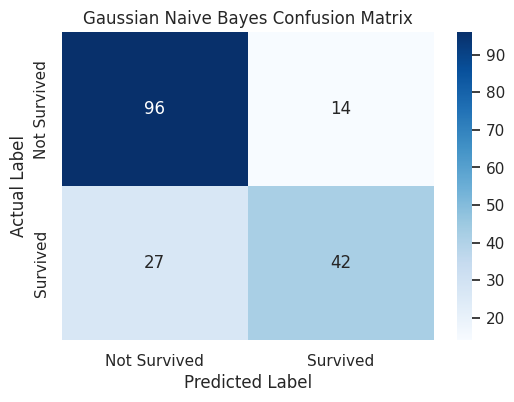

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.78      0.87      0.82       110
    Survived       0.75      0.61      0.67        69

    accuracy                           0.77       179
   macro avg       0.77      0.74      0.75       179
weighted avg       0.77      0.77      0.77       179



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# TODO: print accuracy_score for both y_pred_scratch and y_pred_sklearn
accuracy = accuracy_score(y_test, y_pred_sklearn)

print("GaussianNB Test Accuracy:", accuracy)
print("GaussianNB Test Accuracy (%):", round(accuracy * 100, 2))

# TODO: compute confusion_matrix for y_pred_sklearn and plot it with sns.heatmap(annot=True)
cm = confusion_matrix(y_test, y_pred_sklearn)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('Gaussian Naive Bayes Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# TODO: print classification_report for y_pred_sklearn
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_sklearn,
        target_names=['Not Survived', 'Survived']
    )
)

**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# TODO: build a quick baseline: X_baseline = titanic[['pclass','age','sibsp','parch','fare']] (imputed age only, no encoding/scaling/binning)
X_baseline = titanic[
    ['pclass', 'age', 'sibsp', 'parch', 'fare']
].copy()

y_baseline = titanic['survived']

# TODO: run the same cross_val_score(GaussianNB(), X_baseline, y, cv=5) on it
baseline_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GaussianNB())
])

# TODO: print both mean CV accuracies side-by-side and comment on the difference
baseline_cv_scores = cross_val_score(
    baseline_model,
    X_baseline,
    y_baseline,
    cv=5,
    scoring='accuracy'
)

print("Baseline CV Scores:")
print(baseline_cv_scores)

print("\nBaseline Mean CV Accuracy:",
      baseline_cv_scores.mean())

print("Fully Processed Mean CV Accuracy:",
      cv_scores.mean())


# Percentage comparison
print("\nBaseline Mean CV Accuracy (%):",
      round(baseline_cv_scores.mean() * 100, 2))

print("Fully Processed Mean CV Accuracy (%):",
      round(cv_scores.mean() * 100, 2))


# Difference
difference = cv_scores.mean() - baseline_cv_scores.mean()

print("\nAccuracy Difference (% points):",
      round(difference * 100, 2))

Baseline CV Scores:
[0.60893855 0.67977528 0.66853933 0.70224719 0.7247191 ]

Baseline Mean CV Accuracy: 0.6768438892724876
Fully Processed Mean CV Accuracy: 0.7782034866541908

Baseline Mean CV Accuracy (%): 67.68
Fully Processed Mean CV Accuracy (%): 77.82

Accuracy Difference (% points): 10.14


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

## *Group answers here:*

1. The one-hot encoding of sex, which allowed sex to be included in the model, was probably one of the most important preprocessing steps. Our EDA showed a very large difference in survival rates between female and male passengers: about 74% of females survived compared with about 19% of males. Therefore, making this categorical feature usable by the model provides strong predictive information.

However, the exact contribution of a single preprocessing step cannot be proven from the current experiment alone. To determine it rigorously, we would need an ablation study, where preprocessing steps are removed one at a time and model performance is compared.

2. The hand-computed probability was approximately:

P(Survived = 1 | Female) ≈ 0.742, or 74.2%.

This matched the empirical survival rate calculated directly from the dataset using groupby. They should match because both calculations estimate the same conditional probability from exactly the same observations.

Any extremely small difference would only be caused by floating-point precision or rounding, not by a difference in the underlying probability.

3. We would choose Multinomial Naive Bayes (MultinomialNB).

Spam-detection systems commonly represent documents using features such as the number of times each word appears. These are non-negative discrete count features, which match the assumptions of Multinomial Naive Bayes well.

For example, features could represent:

free = 4, offer = 2, meeting = 0, project = 1

The model then learns how frequently different words occur in spam and non-spam messages.

4. We split the dataset before preprocessing to prevent data leakage.

Operations such as imputation, encoding, power transformation, binning, and scaling learn information from the data. For example, a median imputer learns the median age, a StandardScaler learns the mean and standard deviation, and KBinsDiscretizer learns bin boundaries.

If these were fitted using the entire dataset before splitting, information from the future test set would indirectly influence the training process. This would make the test set no longer completely unseen and could produce an overly optimistic estimate of model performance.

Therefore, the correct pattern is:

Train data → fit preprocessing

Train data → transform

Test data → transform only

This keeps the test set independent and gives a more realistic estimate of how the model will perform on unseen data.